# 01 · Exploración del dataset de salud de astronautas

Plantilla para analizar y revisar el dataset. Cada sección es independiente: copia este notebook (`02-…`, `03-…`) para análisis nuevos.

- Fuentes: reposo en cama de NASA en UTMB (análogo en tierra) e Inspiration4 (vuelo real). Ver `data/processed/LEEME.md`.
- Las columnas `*_sim` **no son datos reales**.
- Para regenerar los datos: `make data`. Para revisar la integridad: `make validate` y `make test`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))  # permite importar astrohealth desde notebooks/

import matplotlib.pyplot as plt
import pandas as pd
from astrohealth import cargar_todo, serie_astronauta
from astrohealth.config import FIGURES, PHENOAGE_ANALITOS
from astrohealth.load import laboratorio_ancho
from astrohealth.validate import revisar

pd.set_option("display.max_columns", 50)
FIGURES.mkdir(parents=True, exist_ok=True)
t = cargar_todo()
d, lab, ev, perf = t["diario"], t["laboratorio"], t["eventos"], t["astronautas"]
{k: v.shape for k, v in t.items()}

{'astronautas': (44, 12),
 'diario': (3034, 40),
 'laboratorio': (9103, 15),
 'eventos': (1053, 13),
 'lineas_base': (40, 17)}

## 1. Revisión de integridad

In [2]:
pd.DataFrame(revisar(), columns=["regla", "ok", "detalle"])

,regla,ok,detalle
0,Sin días duplicados por astronauta,True,0 duplicados
1,"pulso_lpm dentro de [30, 200]",True,0 fuera de rango
2,"pas_mmhg dentro de [70, 220]",True,0 fuera de rango
3,"pad_mmhg dentro de [35, 140]",True,0 fuera de rango
4,"resp_rpm dentro de [6, 40]",True,0 fuera de rango
5,"temp_c dentro de [34.0, 40.5]",True,0 fuera de rango
6,"peso_kg dentro de [30, 200]",True,0 fuera de rango
7,Fases válidas,True,0 sin fase
8,dia_mision coherente con BR_Day (≤ 4 errores c...,True,4 filas
9,Columnas simuladas presentes y marcadas,True,"animo_0a10_sim, hrv_rmssd_ms_sim, spo2_pct_sim..."


## 2. Quién tiene qué datos

In [3]:
perf.groupby("fuente")[["vitales", "sueno", "cognicion", "tilt", "laboratorio"]].agg(lambda s: (s == "si").sum())

,vitales,sueno,cognicion,tilt,laboratorio
fuente,,,,,
"Inspiration4 (vuelo real, 3 días, sept. 2021)",0,0,0,0,4
"UTMB (reposo en cama, análogo de microgravedad)",29,3,29,26,31


## 3. Signos vitales por fase (UTMB)

In [4]:
vit = ["pulso_lpm", "pas_mmhg", "pad_mmhg", "temp_c", "resp_rpm", "peso_kg"]
d.groupby("fase", observed=True)[vit].agg(["mean", "std", "count"]).round(2).T

fase                pre   mision    post
pulso_lpm mean    69.26    70.62   76.05
          std     12.23    11.91   14.26
          count  394.00  2176.00  359.00
pas_mmhg  mean   116.01   116.16  114.99
          std     10.35    10.86   12.33
          count  395.00  2184.00  359.00
pad_mmhg  mean    70.05    71.43   69.16
          std      9.61     8.72    9.70
          count  395.00  2184.00  359.00
temp_c    mean    36.50    36.53   36.49
          std      0.40     0.37    0.41
          count  369.00  2078.00  350.00
resp_rpm  mean    16.91    16.93   16.99
          std      1.48     1.63    1.71
          count  394.00  2179.00  358.00
peso_kg   mean    74.96    73.99   73.20
          std     14.60    14.99   14.08
          count  377.00  2161.00  357.00

## 4. Semáforo por fase

estado_vitales,verde,amarillo,rojo
fase,,,
pre,0.889,0.109,0.003
mision,0.799,0.146,0.055
post,0.638,0.203,0.159


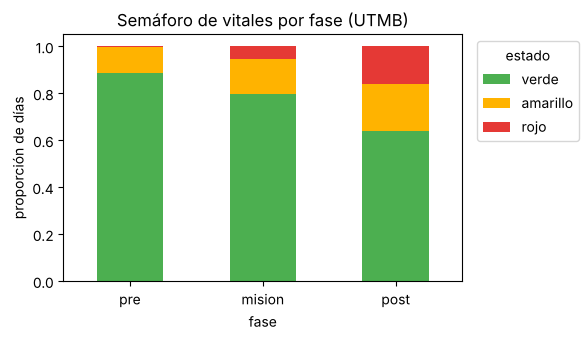

In [5]:
sem = pd.crosstab(d["fase"], d["estado_vitales"], normalize="index").round(3)
ax = sem.plot.bar(stacked=True, color=["#4caf50", "#ffb300", "#e53935"], figsize=(6, 3.5), rot=0)
ax.set_ylabel("proporción de días"); ax.legend(title="estado", bbox_to_anchor=(1.02, 1), loc="upper left"); ax.set_title("Semáforo de vitales por fase (UTMB)")
plt.tight_layout(); plt.savefig(FIGURES / "semaforo_por_fase.png", dpi=150); sem

## 5. Serie de un astronauta
Cambia `ASTRONAUTA` para revisar otro (ver `perf` para los que tienen vitales).

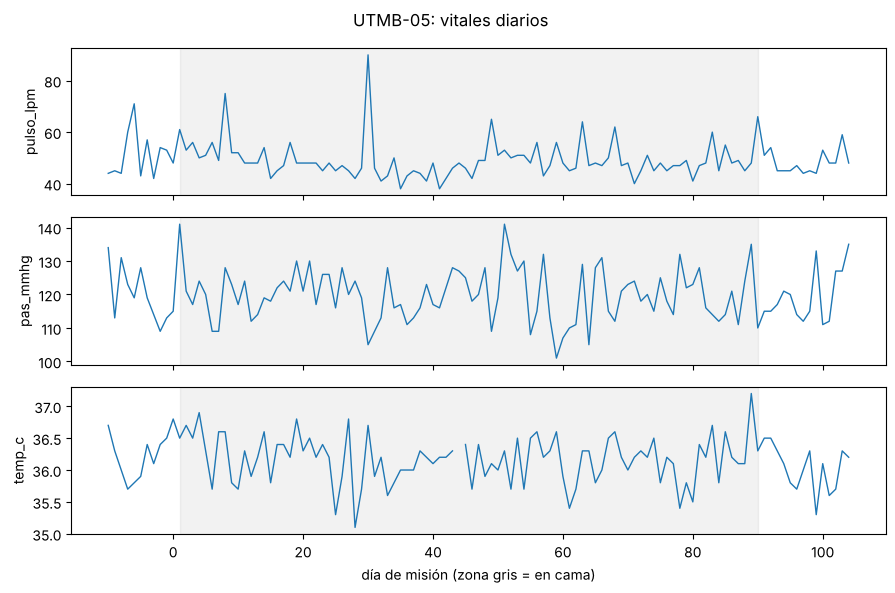

In [6]:
ASTRONAUTA = "UTMB-05"
s = serie_astronauta(ASTRONAUTA, ["pulso_lpm", "pas_mmhg", "temp_c", "estado_vitales"])
fig, axs = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
for ax, col in zip(axs, ["pulso_lpm", "pas_mmhg", "temp_c"]):
    ax.plot(s["dia_mision"], s[col], lw=1)
    ax.axvspan(1, s.loc[s["fase"] == "mision", "dia_mision"].max(), color="grey", alpha=0.1)
    ax.set_ylabel(col)
axs[-1].set_xlabel("día de misión (zona gris = en cama)")
fig.suptitle(f"{ASTRONAUTA}: vitales diarios"); plt.tight_layout()
plt.savefig(FIGURES / f"serie_{ASTRONAUTA}.png", dpi=150)

## 6. Prueba ortostática (tilt)

In [7]:
d.dropna(subset=["tilt_aumento_pulso_lpm"]).groupby("fase", observed=True)["tilt_aumento_pulso_lpm"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
fase,,,,,,,,
pre,26.0,34.1,10.2,17.7,26.6,34.6,37.6,58.7
mision,11.0,56.9,12.6,35.1,50.6,60.9,65.6,73.0
post,41.0,43.8,16.9,-28.0,35.4,43.6,52.6,73.7


## 7. Inspiration4: antes vs después del vuelo

In [8]:
i4 = lab[lab["fuente"].str.startswith("Inspiration4") & lab["analito"].isin(["leucocitos", "linfocitos_abs", "glucosa", "fosfatasa_alcalina"])]
i4.pivot_table(index="analito", columns="dia_relativo", values="valor", aggfunc="mean").round(2)

dia_relativo,-92.0,-44.0,-3.0,1.0,45.0,82.0,194.0
analito,,,,,,,
fosfatasa_alcalina,53.75,55.25,49.75,56.50,55.50,54.50,54.00
glucosa,82.25,74.25,69.50,93.25,84.00,82.00,82.00
leucocitos,6.53,6.65,8.65,6.40,6.48,6.72,6.75
linfocitos_abs,2048.67,1884.25,2910.75,1855.25,2334.25,2356.50,2319.75


## 8. Cobertura de PhenoAge
Falta la edad y el intercepto de la fórmula (ver `docs/12-inspiration4-cmp-phenoage.md`).

In [9]:
ancho = laboratorio_ancho(lab, PHENOAGE_ANALITOS)
ancho.assign(completa=ancho[PHENOAGE_ANALITOS].notna().all(axis=1)).groupby("origen")["completa"].agg(["sum", "count"])

,sum,count
origen,,
Inspiration4,23,28
UTMB,110,117


## 9. Síntomas reportados

In [10]:
ev["categoria"].value_counts().head(10)

categoria
Otro                      298
Dolor (otro)              268
Dolor de cabeza           231
Dificultad para dormir     86
Estreñimiento              41
Dolor de espalda           29
Mareo                      20
Piel seca                  20
Menstrual Cramps           11
itchiness to both legs      2
Name: count, dtype: int64

## 10. Tus análisis
Agrega aquí tus celdas. Guarda las figuras en `FIGURES`.